In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import fdrcorrection as fdr
import scanpy as sc
import anndata

In [48]:
pvals = pd.read_csv('../../plots/02b-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_pval.csv')
pvals.rename(columns={'Unnamed: 0':'pathway'}, inplace = True)
pvals_melt = pd.melt(pvals, id_vars=['pathway'], value_vars=['QSM', 'R1', 'R2s', 'MTsat'])
pvals_melt['padj'] = pd.DataFrame(fdr(pvals_melt['value'], alpha=0.05, method='indep', is_sorted=False)).T[1]
pvals_pivot = pd.pivot_table(pvals_melt, values='padj', index=['pathway'],
                       columns=['variable'])

R2 = pd.read_csv('../../plots/02b-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_R2.csv')

R2.rename(columns={'Unnamed: 0':'pathway'}, inplace = True)
R2.set_index('pathway', inplace = True)
R2 = R2[['QSM','R1','R2s','MTsat']]

In [51]:
sig_pvals = pvals_pivot.loc[(pvals_pivot <0.05).any(axis=1)].index
sig_R2 = R2.loc[(R2 > 0.85).any(axis=1)].index
#R2[R2['GO_term'].isin()]

In [52]:
sig_R2

Index(['inflammation_GO0006954', 'inflammation_GO1904045', 'iron_GO0005375',
       'iron_GO0005384', 'iron_GO0035434', 'iron_GO0045340', 'iron_GO0071421',
       'iron_GO1901671', 'lipid_GO0000123', 'lipid_GO0000138',
       ...
       'myelin_GO0008366', 'myelin_GO0014003', 'myelin_GO0019911',
       'myelin_GO0021530', 'myelin_GO0031643', 'myelin_GO0033269',
       'myelin_GO0042552', 'myelin_GO0043218', 'myelin_GO0048713',
       'myelin_GO0070447'],
      dtype='object', name='pathway', length=140)

In [43]:
pvals_pivot

variable,MTsat,QSM,R1,R2s
Unnamed: 0,,,,
inflammation_GO0001660,0.000044,0.004726,0.000040,0.000073
inflammation_GO0001774,0.000101,0.027443,0.000088,0.000311
inflammation_GO0001788,0.000136,0.005241,0.000155,0.000258
inflammation_GO0002232,0.120499,0.093742,0.107250,0.083491
inflammation_GO0002248,0.028900,0.009181,0.029240,0.017075
...,...,...,...,...
myelin_GO0048715,0.175927,0.523739,0.199418,0.287221
myelin_GO0070445,0.016930,0.077614,0.014827,0.017202
myelin_GO0070447,0.000010,0.006291,0.000025,0.000072


In [39]:
sig_pvals

Index(['inflammation_GO0001660', 'inflammation_GO0001774',
       'inflammation_GO0001788', 'inflammation_GO0002248',
       'inflammation_GO0002265', 'inflammation_GO0002269',
       'inflammation_GO0002282', 'inflammation_GO0002437',
       'inflammation_GO0002438', 'inflammation_GO0002523',
       ...
       'myelin_GO0043217', 'myelin_GO0043218', 'myelin_GO0043219',
       'myelin_GO0043220', 'myelin_GO0043615', 'myelin_GO0045163',
       'myelin_GO0048709', 'myelin_GO0048713', 'myelin_GO0070445',
       'myelin_GO0070447'],
      dtype='object', name='pathway', length=1904)

In [ ]:
sig_R2

In [12]:
pvals = pd.read_csv('../../plots/02b-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_pval.csv')
pvals_melt = pd.melt(pvals, id_vars=['Unnamed: 0'], value_vars=['QSM', 'R1', 'R2s', 'MTsat'])
pvals_melt['padj'] = pd.DataFrame(fdr(pvals_melt['value'], alpha=0.05, method='indep', is_sorted=False)).T[1]
pvals_pivot = pd.pivot_table(pvals_melt, values='padj', index=['Unnamed: 0'],
                       columns=['variable'])
pvals_melt['GO_category'] = pvals_melt['Unnamed: 0'].str.split('_', expand = True)[0]
R2 = pd.read_csv('../../plots/02b-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_R2.csv')
R2_melt = pd.melt(R2, id_vars=['Unnamed: 0'], value_vars=['QSM', 'R1', 'R2s', 'MTsat'])
R2_melt.rename(columns={'value' : 'R2'}, inplace = True)
new_df = pd.merge(
    left=pvals_melt, 
    right=R2_melt,
    how='left',
    left_on=['Unnamed: 0', 'variable'],
    right_on=['Unnamed: 0', 'variable'],
)
new_df

,Unnamed: 0,variable,value,padj,GO_category,R2
0,inflammation_GO0001660,QSM,2.443093e-03,0.004726,inflammation,0.519182
1,inflammation_GO0001774,QSM,1.920554e-02,0.027443,inflammation,0.354437
2,inflammation_GO0001788,QSM,2.757449e-03,0.005241,inflammation,0.510640
3,inflammation_GO0002232,QSM,7.471632e-02,0.093742,inflammation,0.224063
4,inflammation_GO0002248,QSM,5.402658e-03,0.009181,inflammation,0.460658
...,...,...,...,...,...,...
9263,myelin_GO0048715,MTsat,1.489916e-01,0.175927,myelin,0.153275
9264,myelin_GO0070445,MTsat,1.107347e-02,0.01693,myelin,0.402494
9265,myelin_GO0070447,MTsat,7.952339e-08,0.00001,myelin,0.898435
9266,myelin_GO0097252,MTsat,5.655342e-01,0.600111,myelin,0.026048


In [3]:
pvals

,Unnamed: 0,QSM,R1,R2s,MTsat
0,inflammation_GO0001660,0.002443,1.440873e-06,0.000006,1.853632e-06
1,inflammation_GO0001774,0.019206,8.729623e-06,0.000080,1.188351e-05
2,inflammation_GO0001788,0.002757,2.704198e-05,0.000061,2.148087e-05
3,inflammation_GO0002232,0.074716,8.669818e-02,0.065744,9.862991e-02
4,inflammation_GO0002248,0.005403,2.063039e-02,0.011196,2.036187e-02
...,...,...,...,...,...
2312,myelin_GO0048715,0.486612,1.708439e-01,0.254371,1.489916e-01
2313,myelin_GO0070445,0.060656,9.488395e-03,0.011298,1.107347e-02
2314,myelin_GO0070447,0.003436,3.608122e-07,0.000005,7.952339e-08
2315,myelin_GO0097252,0.292194,6.082979e-01,0.571508,5.655342e-01


In [15]:
R2.rename(columns={'Unnamed: 0':'pathway'}, inplace = True)


In [33]:
adata = sc.AnnData(R2[['pathway','QSM','R1','R2s','MTsat']].set_index('pathway'), 
    R2[['pathway','GO.category']].set_index('pathway'), 
    R2[['QSM','R1','R2s','MTsat']].columns.to_frame())

/tmp/ipykernel_2031609/1060038199.py:1: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata = sc.AnnData(R2[['pathway','QSM','R1','R2s','MTsat']].set_index('pathway'),


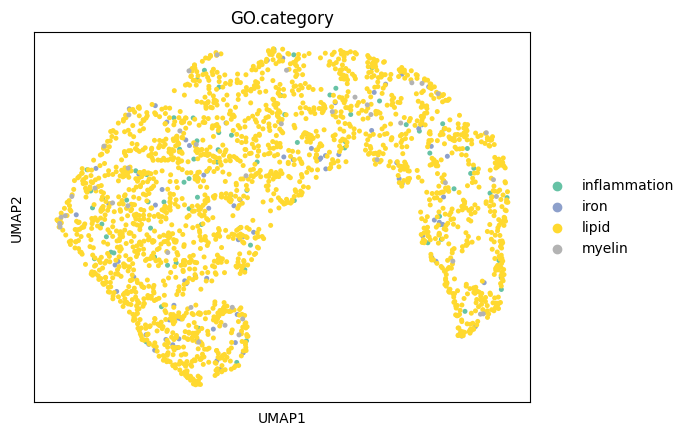

In [34]:
sc.tl.pca(adata)

sc.pp.neighbors(adata)

sc.tl.umap(adata)

sc.pl.umap(adata, color='GO.category', palette = 'Set2')

In [28]:
sc.tl.pca(adata)

In [30]:
adata.uns['pca']

{'params': {'zero_center': True, 'use_highly_variable': False},
 'variance': array([3.6966407 , 0.29611516, 0.00612014], dtype=float32),
 'variance_ratio': array([0.9241602 , 0.07402879, 0.00153003], dtype=float32)}

In [18]:
R2

,pathway,QSM,R1,R2s,MTsat,GO.category
0,inflammation_GO0001660,0.519182,0.842073,0.806262,0.835911,inflammation
1,inflammation_GO0001774,0.354437,0.792459,0.710403,0.782551,inflammation
2,inflammation_GO0001788,0.510640,0.753824,0.721617,0.762221,inflammation
3,inflammation_GO0002232,0.224063,0.208956,0.236954,0.195773,inflammation
4,inflammation_GO0002248,0.460658,0.347975,0.401564,0.349162,inflammation
...,...,...,...,...,...,...
2312,myelin_GO0048715,0.037946,0.139161,0.098606,0.153275,myelin
2313,myelin_GO0070445,0.245019,0.415442,0.400796,0.402494,myelin
2314,myelin_GO0070447,0.494774,0.872080,0.807299,0.898435,myelin
2315,myelin_GO0097252,0.084845,0.020776,0.025266,0.026048,myelin
